# How probing reveals a model weakness
## A visual walkthrough of fixed and adaptive queries

This notebook demonstrates the **manual probe relay** with the intentionally weakened XNOR classifier. The examples are locally generated demonstrations—not reviewer responses. Each session gets **four rounds of eight inputs** and sees the original model's logits. No ablations, labels, or private evaluation samples are returned by the relay.

The operator knows the intended XNOR task for interpreting this illustration. What a future reviewer is told about the task and what feedback they receive must be specified before a formal study.

In [2]:
from pathlib import Path
import sys, tempfile
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

ROOT = Path.cwd().resolve()
if not (ROOT / 'experiment.json').exists():
    ROOT = ROOT.parent
if not (ROOT / 'experiment.json').exists():
    raise FileNotFoundError('Open the notebook from the project root or notebooks/ directory.')
sys.path.insert(0, str(ROOT / 'src'))
from weight_reader.probe import start_session, probe_round
from weight_reader.model import WeightReaderMLP
import json
config = json.loads((ROOT / 'experiment.json').read_text())
checkpoint = ROOT / 'checkpoints' / 'editing_start_seed_11.pt'
OUT = ROOT / 'results' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white'})
def export(fig, name):
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight', facecolor='white')
    fig.savefig(OUT / f'{name}.svg', bbox_inches='tight', facecolor='white')

# Temporary directories keep illustrative transcripts out of the real response collection.
temporary = tempfile.TemporaryDirectory(prefix='weight-reader-probe-demo-')
demo_root = Path(temporary.name)
for condition in ('fixed_probes', 'adaptive_probes'):
    start_session(demo_root, condition, checkpoint, condition, config)
print('Created temporary fixed and adaptive sessions; each is limited to 4 rounds × 8 inputs.')

Created temporary fixed and adaptive sessions; each is limited to 4 rounds × 8 inputs.


## 1. What is a probe?

A probe is a chosen four-number input. The model returns a **logit**: positive means class 1; zero or negative means class 0. Its magnitude is an uncalibrated model score, not a probability or a direct measure of correctness.

Fixed probes are predetermined. Adaptive probes can be selected after seeing earlier results. The two conditions use the same model and the same total number of queries.

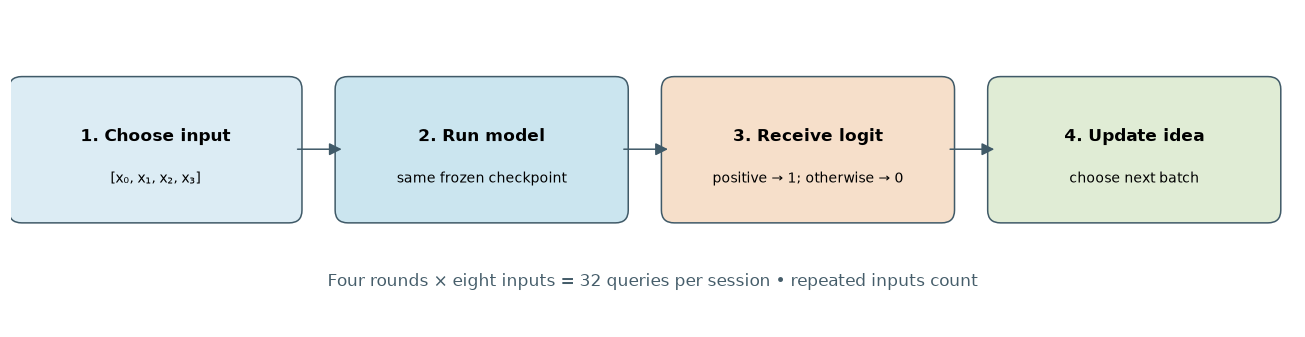

In [3]:
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 3); ax.axis('off')
boxes = [(0.1, '1. Choose input', '[x₀, x₁, x₂, x₃]', '#dcecf4'),
         (3.15, '2. Run model', 'same frozen checkpoint', '#cbe5ef'),
         (6.2, '3. Receive logit', 'positive → 1; otherwise → 0', '#f6dfca'),
         (9.25, '4. Update idea', 'choose next batch', '#e0ecd5')]
for x, title, sub, color in boxes:
    ax.add_patch(FancyBboxPatch((x, 1.1), 2.5, 1.15, boxstyle='round,pad=.12', facecolor=color, edgecolor='#405a68'))
    ax.text(x+1.25, 1.8, title, ha='center', va='center', weight='bold')
    ax.text(x+1.25, 1.4, sub, ha='center', va='center', fontsize=9)
for x in (2.65, 5.7, 8.75):
    ax.add_patch(FancyArrowPatch((x, 1.68), (x+.47, 1.68), arrowstyle='-|>', mutation_scale=17, color='#405a68'))
ax.text(6, .38, 'Four rounds × eight inputs = 32 queries per session • repeated inputs count', ha='center', color='#455d6a')
fig.tight_layout(); export(fig, '05_probe_workflow'); plt.show()

## 2. Fixed probes: balanced coverage

Each fixed batch contains two inputs in each quadrant of (x₀, x₁). The relay generates the same fixed inputs for every session from the configured seed. Here we run all four rounds and plot them; x₂ and x₃ also vary, even though this plot shows only the first two coordinates.

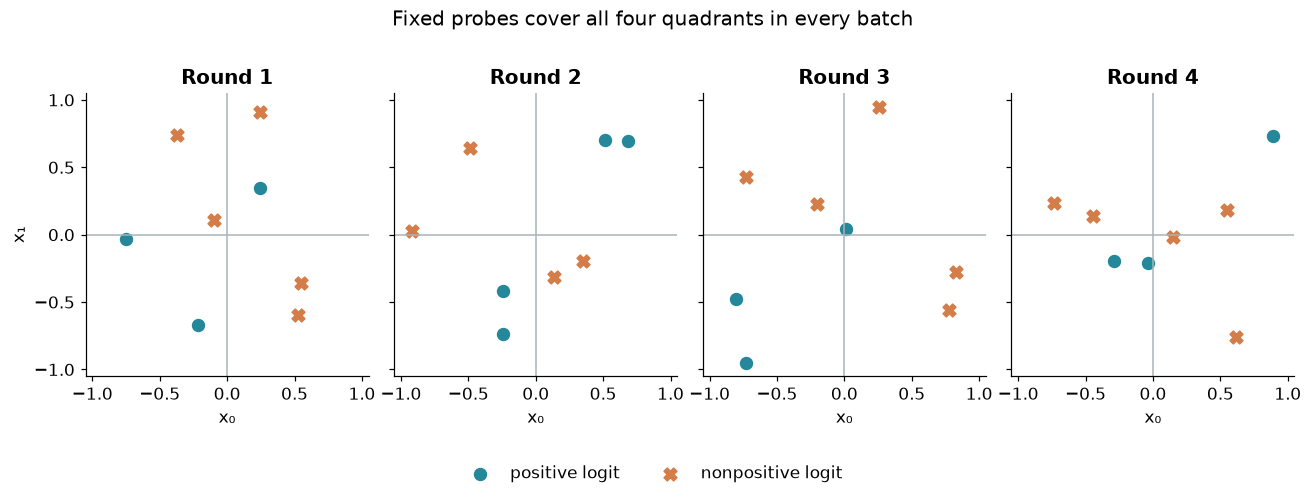

Fixed probe count: 32


In [6]:
fixed_rounds = [probe_round(demo_root, 'fixed_probes', i) for i in range(1, 5)]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6), sharex=True, sharey=True)
for round_id, (ax, result) in enumerate(zip(axes, fixed_rounds), 1):
    inputs = np.array(result['inputs']); logits = np.array(result['logits'])
    ax.axhline(0, color='#a8b4b9', lw=1); ax.axvline(0, color='#a8b4b9', lw=1)
    ax.scatter(inputs[logits > 0, 0], inputs[logits > 0, 1], c='#24879a', marker='o', s=60, label='positive logit')
    ax.scatter(inputs[logits <= 0, 0], inputs[logits <= 0, 1], c='#d47d48', marker='X', s=70, label='nonpositive logit')
    ax.set(xlim=(-1.05,1.05), ylim=(-1.05,1.05), xlabel='x₀', title=f'Round {round_id}'); ax.set_aspect('equal')
axes[0].set_ylabel('x₁')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -.2))
fig.suptitle('Fixed probes cover all four quadrants in every batch', y=1.03, fontsize=13)
fig.tight_layout(); export(fig, '06_fixed_probes'); plt.show()
print('Fixed probe count:', sum(len(r['inputs']) for r in fixed_rounds))

## 3. Adaptive probes: follow a hypothesis

This **scripted illustration** uses four batches that focus increasingly on Q++, where both relevant inputs are positive. The first batch surveys the quadrants; later batches vary the ratio between x₀ and x₁. A real reviewer would choose subsequent batches after receiving earlier results; the choices below were authored for this explanation.

For the known XNOR task, positive x₀ and x₁ should produce class 1. If a Q++ query returns a nonpositive logit, the model disagrees with the known target for that input. The relay itself returns only the input and logit—not this interpretation.

In [4]:
adaptive_batches = [
    {'hypothesis':'Survey the four sign quadrants.', 'inputs':[[.5,.5,0,0],[.8,.2,0,0],[.5,-.5,0,0],[-.5,.5,0,0],[-.5,-.5,0,0],[-.2,-.8,0,0],[.2,.8,0,0],[-.8,-.2,0,0]]},
    {'hypothesis':'Compare balanced and unbalanced positive inputs.', 'inputs':[[.5,.5,0,0],[.6,.4,0,0],[.7,.3,0,0],[.8,.2,0,0],[.4,.6,0,0],[.3,.7,0,0],[.2,.8,0,0],[.1,.9,0,0]]},
    {'hypothesis':'Vary nuisance inputs at selected positive coordinates.', 'inputs':[[.8,.2,a,b] for a,b in [(0,0),(.8,0),(-.8,0),(0,.8),(0,-.8),(.8,.8),(-.8,-.8),(.8,-.8)]]},
    {'hypothesis':'Refine the transition as the positive-coordinate ratio changes.', 'inputs':[[v,1-v,0,0] for v in [.05,.15,.25,.35,.65,.75,.85,.95]]},
]
adaptive_rounds = []
for i, batch in enumerate(adaptive_batches, 1):
    adaptive_rounds.append(probe_round(demo_root, 'adaptive_probes', i, batch))
print('Adaptive probe count:', sum(len(r['inputs']) for r in adaptive_rounds))
print('Repeated inputs are included in this count.')

Adaptive probe count: 32
Repeated inputs are included in this count.


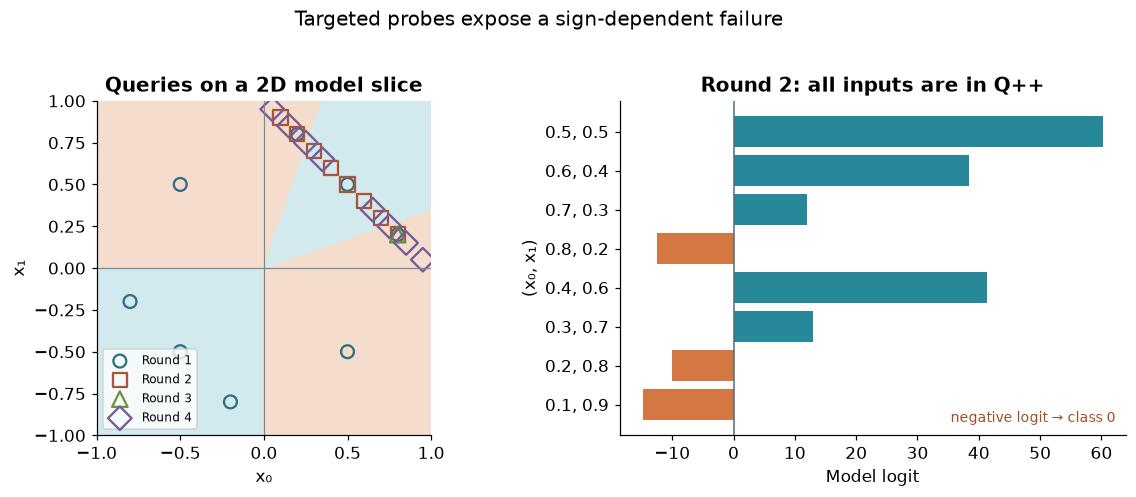

In [5]:
# All plotted probes fix x₂ = x₃ = 0; this is one slice of a four-dimensional model.
points = np.linspace(-1, 1, 201)
xx, yy = np.meshgrid(points, points)
grid = torch.tensor(np.column_stack([xx.ravel(), yy.ravel(), np.zeros(xx.size), np.zeros(xx.size)]), dtype=torch.float32)
model = WeightReaderMLP(); model.load_state_dict(torch.load(checkpoint, map_location='cpu', weights_only=True)); model.eval()
with torch.no_grad():
    boundary = (model(grid).numpy().reshape(xx.shape) > 0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.pcolormesh(xx, yy, boundary.astype(int), cmap=ListedColormap(['#f5ddce','#d2e9ed']), shading='auto', rasterized=True)
ax.axhline(0,color='#788c95',lw=.8); ax.axvline(0,color='#788c95',lw=.8)
colors = ['#2f7083','#a95637','#738f40','#745a96']
for idx, (result, color) in enumerate(zip(adaptive_rounds, colors), 1):
    data = np.array(result['inputs']); visible = (data[:,2] == 0) & (data[:,3] == 0)
    ax.scatter(data[visible,0], data[visible,1], s=55+idx*16, marker=['o','s','^','D'][idx-1], facecolors='none', edgecolors=color, linewidths=1.5, label=f'Round {idx}')
ax.set(xlim=(-1,1), ylim=(-1,1), xlabel='x₀', ylabel='x₁', title='Queries on a 2D model slice'); ax.set_aspect('equal')
ax.legend(frameon=True, fontsize=8, loc='lower left')
ax = axes[1]
round2 = adaptive_rounds[1]
rows = np.array(round2['inputs']); logits = np.array(round2['logits']); labels = [f'{r[0]:.1f}, {r[1]:.1f}' for r in rows]
bars = ax.barh(np.arange(len(labels)), logits, color=np.where(logits > 0, '#27889a', '#d47743'))
ax.axvline(0, color='#536a74', lw=1)
ax.set(yticks=np.arange(len(labels)), yticklabels=labels, xlabel='Model logit', ylabel='(x₀, x₁)', title='Round 2: all inputs are in Q++')
ax.invert_yaxis()
ax.text(.98, .04, 'negative logit → class 0', ha='right', transform=ax.transAxes, color='#a64b24', fontsize=9)
fig.suptitle('Targeted probes expose a sign-dependent failure', y=1.02, fontsize=13)
fig.tight_layout(); export(fig, '07_adaptive_probe_example'); plt.show()

## 4. What gets recorded?

The relay writes the input/logit pairs for each round to a transcript and stores the session checkpoint and hash separately. Running the same round again with the same inputs returns the recorded result without adding a query. Reusing a round number with different inputs is rejected. Duplicate inputs within new rounds count toward the budget.

The table below displays one batch from this temporary demonstration. Values are logits from the frozen weakened model, not labels or neuron-ablation results.

In [6]:
sample = adaptive_rounds[1]
table = pd.DataFrame(sample['inputs'], columns=['x₀','x₁','x₂','x₃'])
table['logit'] = sample['logits']
table['predicted class'] = (table['logit'] > 0).astype(int)
print(table.to_string(index=False, float_format=lambda v: f'{v:.3f}'))
replayed = probe_round(demo_root, 'adaptive_probes', 2, adaptive_batches[1])
print('\nReplay returns identical saved result:', replayed == sample)
print('\nDemo sessions are temporary; no reviewer transcript is created.')

   x₀    x₁    x₂    x₃   logit  predicted class
0.500 0.500 0.000 0.000  60.207                1
0.600 0.400 0.000 0.000  38.472                1
0.700 0.300 0.000 0.000  11.926                1
0.800 0.200 0.000 0.000 -12.542                0
0.400 0.600 0.000 0.000  41.281                1
0.300 0.700 0.000 0.000  12.993                1
0.200 0.800 0.000 0.000 -10.031                0
0.100 0.900 0.000 0.000 -14.823                0

Replay returns identical saved result: True

Demo sessions are temporary; no reviewer transcript is created.


## From probes to an edit

A future reviewer could use the observed pattern and the model weights to propose a specific edit, then freeze that proposal before held-out evaluation. The controlled weakness and reference checkpoint must stay hidden from a blinded reviewer. Probe outputs alone do not identify a unique internal mechanism, and a successful known repair is not evidence that a reviewer found it.

The current relay implements the probe budget and transcript. Ablation-review packet export is available. Formal edit submission and held-out scoring remain future work.